# Exploratory Data Analysis (EDA)

Exploratory analysis of the 18 binary molecular properties (12 `Tox21`, 5 `CYP450`, 1 `hERG_Karim`):
- **Section 0**: Setup, data loading, schema and missing values inspection
- **Section 1**: SMILES validation, canonicalization duplicate label conflict check
- **Section 2**: Per-property molecule counts and class imbalance
- **Section 3**: Multi-property coverage and pairwise overlap matrix
- **Section 4**: Chemical elements exploration and identification of moelcules with zero bonds 
- **Section 5**: Scaffold splitting analysis: default from TDC and implemented by us

---
## 0. Setup and dataset inspection

### 0.1 Loading the 18 TDC Datasets
TDC checks `data/raw/` and downloads files only if missing

In [13]:
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from tdc.single_pred import ADME, Tox
from tdc.utils import retrieve_label_name_list

from preprocess import ALL_TASKS, CYP450_TASKS, HERG_TASKS, TOX_21_TASKS, preprocess_cv_datasets, preprocess_datasets

import contextlib, io


RAW_DATA_DIR = Path("data/raw")
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Store each endpoint's TDC DataLoader object and its raw DataFrame (`data.get_data()`)
tdc_loaders = {}
raw_full_dfs = {}

# 1. Load the 12 Tox21 endpoints
for label in retrieve_label_name_list("Tox21"):
    loader = Tox(name="Tox21", label_name=label, path=str(RAW_DATA_DIR))
    tdc_loaders[label] = loader
    raw_full_dfs[label] = loader.get_data()

# 2. Load the 5 CYP450 endpoints
for task in CYP450_TASKS:
    loader = ADME(name=task, path=str(RAW_DATA_DIR))
    tdc_loaders[task] = loader
    raw_full_dfs[task] = loader.get_data()

# 3. Load the hERG_Karim endpoint
for task in HERG_TASKS:
    loader = Tox(name=task, path=str(RAW_DATA_DIR))
    tdc_loaders[task] = loader
    raw_full_dfs[task] = loader.get_data()


Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!
Found local copy...
Loading...
Done!


### 0.2 Raw schema analysis


In [14]:
# Summarize the schema of each raw DataFrame returned by `loader.get_data()`
schema_summary = pd.DataFrame([
    {
        "Endpoint": task,
        "Shape (rows, cols)": df.shape,
        "Columns": list(df.columns),
        "Dtypes": {col: str(dt) for col, dt in df.dtypes.items()},
        "Unique Y Values": sorted(df["Y"].dropna().unique().tolist()),
        "Example Drug_ID": df["Drug_ID"].iloc[0],
        "Example Drug (SMILES)": df["Drug"].iloc[0],
    }
    for task, df in raw_full_dfs.items()
])
display(schema_summary)

print("Sample rows from `raw_full_dfs['NR-AR']`:")
raw_full_dfs["NR-AR"].head(5)


,Endpoint,"Shape (rows, cols)",Columns,Dtypes,Unique Y Values,Example Drug_ID,Example Drug (SMILES)
0,NR-AR,"(7265, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
1,NR-AR-LBD,"(6758, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
2,NR-AhR,"(6549, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
3,NR-Aromatase,"(5821, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
4,NR-ER,"(6193, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O
5,NR-ER-LBD,"(6955, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
6,NR-PPAR-gamma,"(6450, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
7,SR-ARE,"(5832, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
8,SR-ATAD5,"(7072, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1
9,SR-HSE,"(6467, 3)","[Drug_ID, Drug, Y]","{'Drug_ID': 'str', 'Drug': 'str', 'Y': 'float64'}","[0.0, 1.0]",TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1


Sample rows from `raw_full_dfs['NR-AR']`:


,Drug_ID,Drug,Y
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
3,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0
4,TOX5110,CC(C)(C)OOC(C)(C)CCC(C)(C)OOC(C)(C)C,0.0


### 0.3 `NaN' and empty string check
Check for 'NaN' or empty SMILES strings in the tables before extracting SMILES with labels.

In [15]:
# Check for NaN and epty SMILES columns and NaN labels
na_summary = pd.DataFrame([
    {
        "Endpoint": task,
        "Total Rows": len(df),
        "Drug_ID NaNs": int(df["Drug_ID"].isna().sum()),
        "Drug (SMILES) NaNs": int(df["Drug"].isna().sum()),
        "Empty SMILES Strings": int(df["Drug"].dropna().astype(str).str.strip().eq("").sum()),
        "Y (Label) NaNs": int(df["Y"].isna().sum()),
    }
    for task, df in raw_full_dfs.items()
])
display(na_summary)

# Extract only the non-null SMILES column ("Drug") and integer binary target ("Y") for each endpoint
raw_dfs = {
    task: df[["Drug", "Y"]].dropna(subset=["Drug", "Y"]).astype({"Y": int})
    for task, df in raw_full_dfs.items()
}



,Endpoint,Total Rows,Drug_ID NaNs,Drug (SMILES) NaNs,Empty SMILES Strings,Y (Label) NaNs
0,NR-AR,7265,0,0,0,0
1,NR-AR-LBD,6758,0,0,0,0
2,NR-AhR,6549,0,0,0,0
3,NR-Aromatase,5821,0,0,0,0
4,NR-ER,6193,0,0,0,0
5,NR-ER-LBD,6955,0,0,0,0
6,NR-PPAR-gamma,6450,0,0,0,0
7,SR-ARE,5832,0,0,0,0
8,SR-ATAD5,7072,0,0,0,0
9,SR-HSE,6467,0,0,0,0


---
## 1. SMILES validation and canonicalization

Different databases write the same molecule with different atom orderings, which can be unified by the use of canonical SMILES. Here we:
1. Parse each unique raw SMILES using RDKit (`Chem.MolFromSmiles`) and convert valid molecules to canonical SMILES (`Chem.MolToSmiles(mol, canonical=True)`).
2. Filter out invalid SMILES and check whether duplicate canonical SMILES within any task have conflicting labels.

In [16]:
# map each valid raw SMILES string -> canonical RDKit SMILES string
all_raw_smiles = {smile for df in raw_dfs.values() for smile in df["Drug"]}
raw_smiles_to_canonical = {}
invalid_smiles = []
for smiles in all_raw_smiles:
    mol = Chem.MolFromSmiles(smiles) 
    if mol is not None and mol.GetNumAtoms() > 0:
        raw_smiles_to_canonical[smiles] = Chem.MolToSmiles(mol, canonical=True)
    else:
        invalid_smiles.append(smiles)

# extract rows with valid SMILES and group rows with the same canonical SMILES and inspect
canon_rows = []
task_series = {}
for task in ALL_TASKS:
    df = raw_dfs[task]
    df_valid = df[df["Drug"].isin(raw_smiles_to_canonical)].copy() 
    df_valid["canon_smiles"] = df_valid["Drug"].map(raw_smiles_to_canonical) 

    is_already_canon = df_valid["Drug"] == df_valid["canon_smiles"] 
    num_unique_per_mol = df_valid.groupby("canon_smiles")["Y"].nunique()

    task_series[task] = df_valid.drop_duplicates("canon_smiles").set_index("canon_smiles")["Y"]

    canon_rows.append({
        "Prediction task": task,
        "Raw rows": len(df),
        "Invalid SMILES": len(df) - len(df_valid),
        "Already canonical": int(is_already_canon.sum()),
        "Non-canonical": int((~is_already_canon).sum()),
        "Canonical %": round(is_already_canon.mean() * 100, 2),
        "Unique canonical": df_valid["canon_smiles"].nunique(),
        "Conflicting duplicates (0 vs 1)": int((num_unique_per_mol > 1).sum()),
    })

print(f"Unique raw SMILES: {len(all_raw_smiles):,}")
print(f"Unique canonical SMILES: {len(raw_smiles_to_canonical):,}")
print(f"Invalid SMILES: {len(invalid_smiles)}")

print("Invalid SMILES:", invalid_smiles)
display(pd.DataFrame(canon_rows))



[14:12:39] Explicit valence for atom # 4 Al, 6, is greater than permitted
[14:12:39] Explicit valence for atom # 20 Al, 6, is greater than permitted
[14:12:40] Explicit valence for atom # 5 Al, 6, is greater than permitted
[14:12:40] WARNING: not removing hydrogen atom without neighbors
[14:12:41] Explicit valence for atom # 9 Al, 6, is greater than permitted
[14:12:41] Explicit valence for atom # 4 Al, 6, is greater than permitted
[14:12:42] Explicit valence for atom # 3 Al, 6, is greater than permitted
[14:12:43] Explicit valence for atom # 16 Al, 6, is greater than permitted
[14:12:48] Explicit valence for atom # 8 Al, 6, is greater than permitted


Unique raw SMILES: 36,844
Unique canonical SMILES: 36,836
Invalid SMILES: 8
Invalid SMILES: ['CC(=O)O[AlH3](O)O', 'CCCCCCCCCCCCCCCCCC(=O)O[AlH3](O)O', 'CCCCO[AlH3](OCCCC)OCCCC', 'CCOC(=O)/C=C(/C)O[AlH3](OC(C)CC)OC(C)CC', 'CC(=O)O[AlH3](O)OC(C)=O', 'O=CO[AlH3](OC=O)OC=O', 'O=S(=O)(OC[C@H]1O[C@H](O[C@]2(COS(=O)(=O)O[AlH3](O)O)O[C@H](COS(=O)(=O)O[AlH3](O)O)[C@@H](OS(=O)(=O)O[AlH3](O)O)[C@@H]2OS(=O)(=O)O[AlH3](O)O)[C@H](OS(=O)(=O)O[AlH3](O)O)[C@@H](OS(=O)(=O)O[AlH3](O)O)[C@@H]1OS(=O)(=O)O[AlH3](O)O)O[AlH3](O)O.O[AlH3](O)[AlH3](O)O.O[AlH3](O)[AlH3](O)O.O[AlH3](O)[AlH3](O)O.O[AlH3](O)[AlH3](O)O', 'NC(=O)NC1N=C(O[AlH3](O)O)NC1=O']


,Prediction task,Raw rows,Invalid SMILES,Already canonical,Non-canonical,Canonical %,Unique canonical,Conflicting duplicates (0 vs 1)
0,NR-AR,7265,7,6976,282,96.11,7258,0
1,NR-AR-LBD,6758,7,6505,246,96.36,6751,0
2,NR-AhR,6549,7,6293,249,96.19,6542,0
3,NR-Aromatase,5821,6,5610,205,96.47,5815,0
4,NR-ER,6193,7,5968,218,96.48,6186,0
5,NR-ER-LBD,6955,7,6680,268,96.14,6948,0
6,NR-PPAR-gamma,6450,7,6208,235,96.35,6443,0
7,SR-ARE,5832,7,5672,153,97.37,5825,0
8,SR-ATAD5,7072,7,6809,256,96.38,7065,0
9,SR-HSE,6467,7,6271,189,97.07,6460,0


**Conclusions:**
- There are no missing values.
- There are no conflicting duplicate labels (`0` vs `1`) within any property.

---
## 2. Per-property molecule counts and class imbalance

Merge all 18 tasks by canonical SMILES into a matrix `multitask_df` (`36,823` molecules $\times$ `18` properties) and measure:
- Number of molecules labeled per property.
- Positive class rate (`Pos %`) and negative-to-positive ratio (`n_neg / n_pos`), which defines `pos_weight`.

Unified multi-task table shape: 36,823 unique canonical molecules x 18 endpoints


,Endpoint,Labeled Molecules,Label 0 (Neg),Label 1 (Pos),Neg %,Pos %,Imbalance Ratio (num of 0 label)/(num of 1 label),Missing %
0,NR-AR,7258,6950,308,95.76,4.24,22.56,80.29
1,NR-AR-LBD,6751,6514,237,96.49,3.51,27.49,81.67
2,NR-AhR,6542,5774,768,88.26,11.74,7.52,82.23
3,NR-Aromatase,5815,5515,300,94.84,5.16,18.38,84.21
4,NR-ER,6186,5395,791,87.21,12.79,6.82,83.20
5,NR-ER-LBD,6948,6599,349,94.98,5.02,18.91,81.13
6,NR-PPAR-gamma,6443,6257,186,97.11,2.89,33.64,82.50
7,SR-ARE,5825,4883,942,83.83,16.17,5.18,84.18
8,SR-ATAD5,7065,6801,264,96.26,3.74,25.76,80.81
9,SR-HSE,6460,6088,372,94.24,5.76,16.37,82.46


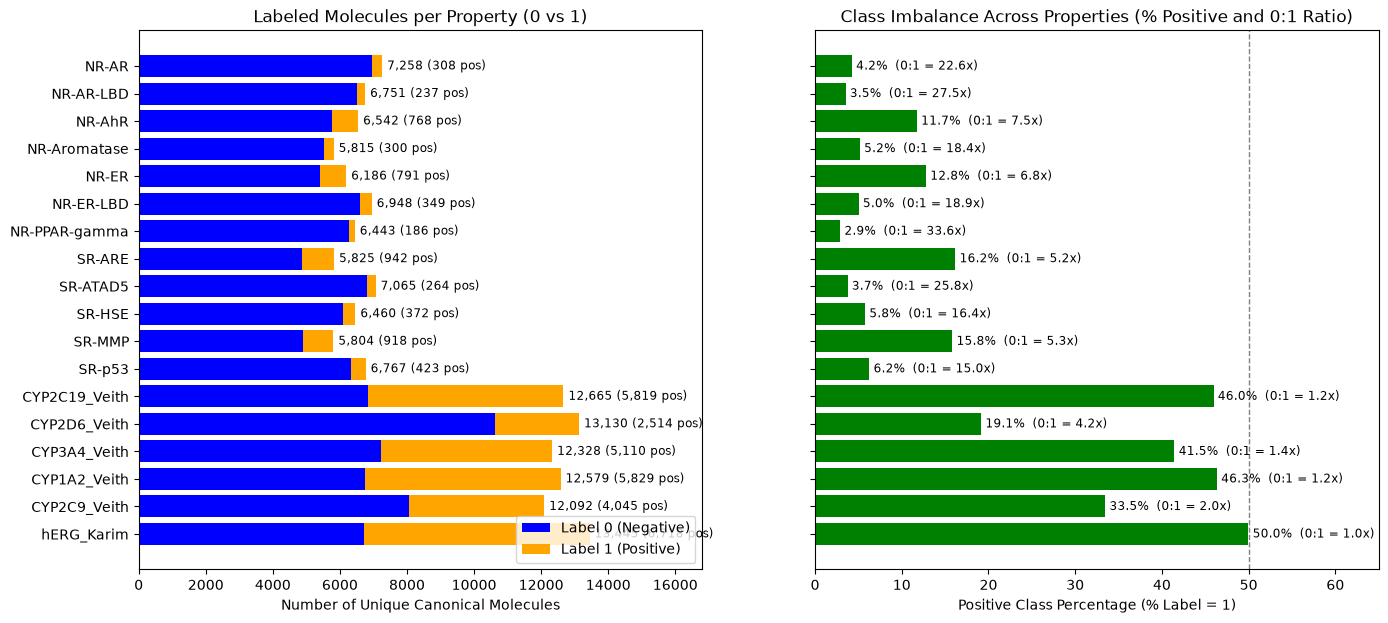

In [17]:
multitask_df = pd.DataFrame(task_series)[ALL_TASKS].sort_index()

print(f"Unified multi-task table shape: {multitask_df.shape[0]:,} unique canonical molecules x {multitask_df.shape[1]} endpoints")

stats_rows = []
for task in ALL_TASKS:
    cleared_col = multitask_df[task].dropna()
    n_neg, n_pos = int((cleared_col == 0).sum()), int((cleared_col == 1).sum())
    stats_rows.append({
        "Endpoint": task,
        "Labeled Molecules": len(cleared_col),
        "Label 0 (Neg)": n_neg,
        "Label 1 (Pos)": n_pos,
        "Neg %": round(n_neg / len(cleared_col) * 100, 2),
        "Pos %": round(n_pos / len(cleared_col) * 100, 2),
        "Imbalance Ratio (num of 0 label)/(num of 1 label)": round(n_neg / n_pos, 2),
        "Missing %": round((1 - (len(cleared_col) / len(multitask_df))) * 100, 2),
    })

stats_df = pd.DataFrame(stats_rows)
display(stats_df)


fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
y_pos = np.arange(len(ALL_TASKS))
neg_counts = stats_df["Label 0 (Neg)"].values
pos_counts = stats_df["Label 1 (Pos)"].values
pos_pcts = stats_df["Pos %"].values
imbalance_ratios = stats_df["Imbalance Ratio (num of 0 label)/(num of 1 label)"].values

# stacked bar chart
axes[0].barh(y_pos, neg_counts, color="blue", label="Label 0 (Negative)")
axes[0].barh(y_pos, pos_counts, left=neg_counts, color="orange", label="Label 1 (Positive)")
axes[0].set_yticks(y_pos, ALL_TASKS)
axes[0].set_xlabel("Number of Unique Canonical Molecules")
axes[0].set_title("Labeled Molecules per Property (0 vs 1)")
axes[0].invert_yaxis()
axes[0].legend(loc="lower right")
for i, (tot, pos) in enumerate(zip(neg_counts + pos_counts, pos_counts)):
    axes[0].text(tot + 150, i, f"{tot:,} ({pos:,} pos)", va="center", fontsize=8.5)
axes[0].set_xlim(0, max(neg_counts + pos_counts) * 1.25)

# Right plot: Positive class percentage and 0:1 imbalance ratio
axes[1].barh(y_pos, pos_pcts, color="green")
axes[1].axvline(50, color="gray", linestyle="--", linewidth=1, label="50% Balanced")
axes[1].set_xlabel("Positive Class Percentage (% Label = 1)")
axes[1].set_title("Class Imbalance Across Properties (% Positive and 0:1 Ratio)")
for i, (pct, ratio) in enumerate(zip(pos_pcts, imbalance_ratios)):
    axes[1].text(pct + 0.5, i, f"{pct:.1f}%  (0:1 = {ratio:.1f}x)", va="center", fontsize=8.5)  
axes[1].set_xlim(0, 65)

plt.show()


**Conclusions:**
- Within-task class imbalance in `Tox21`: positive rates are only `2.9% – 16.2%` (imbalance ratios up to `33.6:1`), while `CYP450` (`19.2% – 46.3%`) and `hERG_Karim` (`50.0%`) are much more balanced.
- Unequal sample counts across tasks: `hERG_Karim` and `CYP450` have $>2\times$ more labels than `Tox21`.

---
## 3. Multi-property coverage and pairwise overlaps

### 3.1 Number of labeled properties per molecule
Count how many of the 18 properties each molecule has labels for.

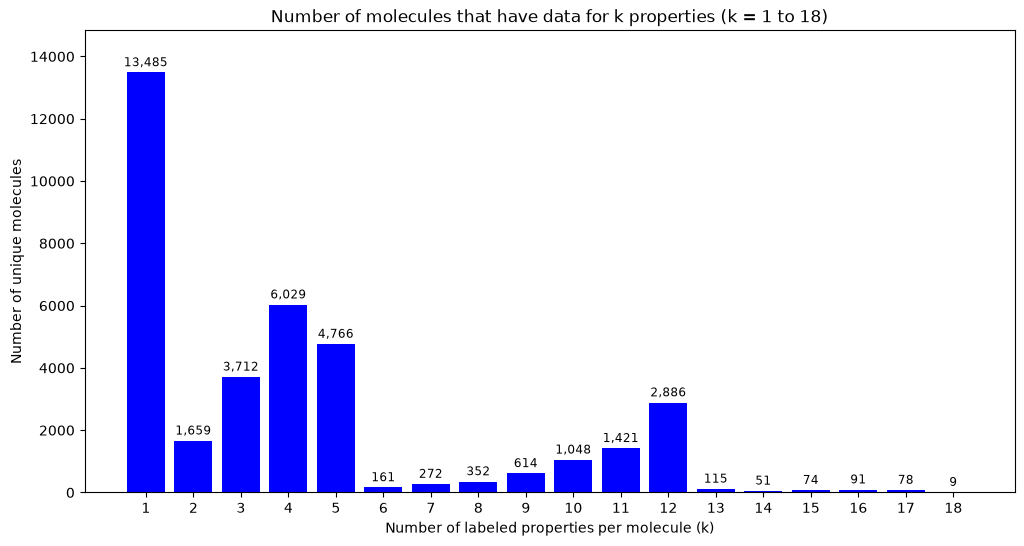

In [18]:
# Count how many of the 18 endpoints are non-null for each unique molecule
endpoints_per_molecule = multitask_df.notna().sum(axis=1)

coverage_df = pd.DataFrame([
    {
        "Number of properties labeled (k)": k,
        "Number of molecules with exactly k properties labeled": int((endpoints_per_molecule == k).sum()),
        "% of molecules": round((endpoints_per_molecule == k).mean() * 100, 2),
        "Number of molecules with >= k properties labeled": int((endpoints_per_molecule >= k).sum()),
        "Cumulative % of molecules": round((endpoints_per_molecule >= k).mean() * 100, 2),
    }
    for k in range(1, len(ALL_TASKS) + 1)
])
coverage_df

# Bar chart of molecule counts by number of labeled endpoints k = 1..18
plt.figure(figsize=(12, 6))
plt.bar(
    coverage_df["Number of properties labeled (k)"],
    coverage_df["Number of molecules with exactly k properties labeled"],
    color="blue",
)
plt.xticks(range(1, 19))
plt.xlabel("Number of labeled properties per molecule (k)")
plt.ylabel("Number of unique molecules")
plt.title("Number of molecules that have data for k properties (k = 1 to 18)")
for k_val, molecule_count in zip(
    coverage_df["Number of properties labeled (k)"],
    coverage_df["Number of molecules with exactly k properties labeled"],
):
    plt.text(k_val, molecule_count + 200, f"{molecule_count:,}", ha="center", fontsize=8.5)
plt.ylim(0, coverage_df["Number of molecules with exactly k properties labeled"].max() * 1.1)
plt.show()


### 3.2 Pairwise overlap matrix
Compute how many molecules have labels for every pair of properties.

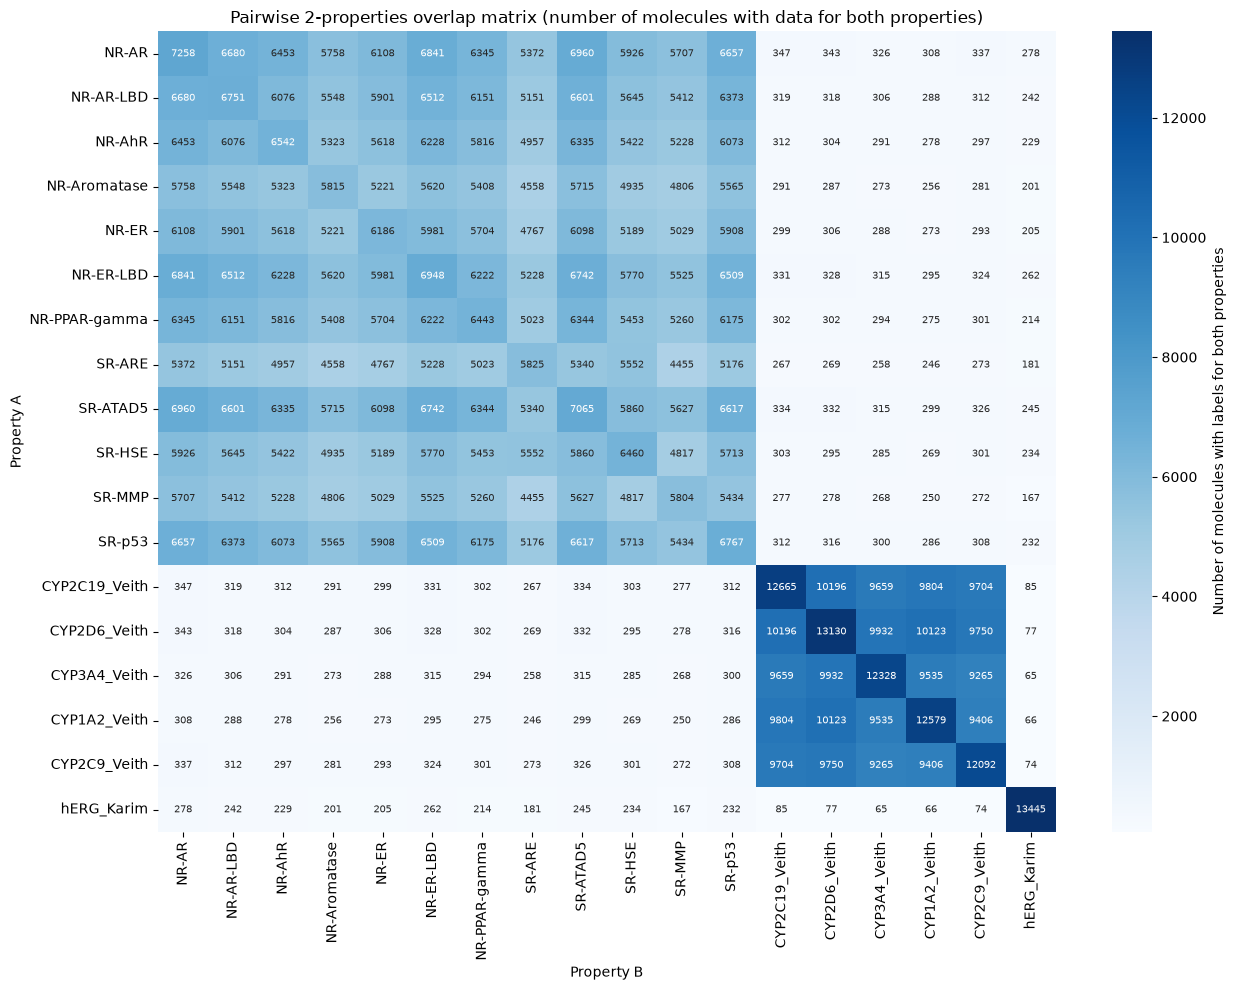

In [19]:
# Compute the 18 x 18 pairwise overlap matrix: 
# 1. get the indicator matrix A: A[mol, prop] = 1 if molecule mol has a label for property prop
# 2. (A^T @ A)[i, j] = number molecules labeled for both properties i and j
not_null_indicator = multitask_df.notna().astype(int)
overlap_matrix = not_null_indicator.T @ not_null_indicator

plt.figure(figsize=(13, 10))
sns.heatmap(
    overlap_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    annot_kws={"size": 7.5},
    cbar_kws={"label": "Number of molecules with labels for both properties"},
)
plt.title("Pairwise 2-properties overlap matrix (number of molecules with data for both properties)")
plt.xlabel("Property B")
plt.ylabel("Property A")
plt.tight_layout()
plt.show()


---
## 4. Analysis of chemical elements and number of bonds in the molecules.

### 4.1 Check for molecules with zero covalent bonds and chemical element frequencies
Inspect bond counts and chemical element frequencies to identify unrepresentative outliers that should be excluded before GNN training.

In [24]:
pt = Chem.GetPeriodicTable() 
atom_counts, mol_counts = Counter(), Counter()
zero_bond_smiles = []

for canonical_smiles in multitask_df.index:
    mol = Chem.MolFromSmiles(canonical_smiles)
    symbols = [a.GetSymbol() for a in mol.GetAtoms()]

    atom_counts.update(symbols)
    mol_counts.update(set(symbols))
    
    if mol.GetNumBonds() == 0:
        zero_bond_smiles.append(canonical_smiles)


print(f"Total unique canonical molecules: {len(multitask_df):,}")
print(f"Number of molecules with no bonds: {len(zero_bond_smiles):,} ({len(zero_bond_smiles) / len(multitask_df) * 100:.2f}%)")
print(f"SMILES with 0 covalent bonds: {zero_bond_smiles}")

elem_df = pd.DataFrame([
    {
        "Symbol": symbol,
        "Atomic number": pt.GetAtomicNumber(symbol),
        "Molecules": mol_count,
        "Is in % of molecules": round(mol_count / len(multitask_df) * 100, 3),
        "Total atoms in dataset": atom_counts[symbol],
    }
    for symbol, mol_count in mol_counts.most_common()
])
display(elem_df)


Total unique canonical molecules: 36,823
Number of molecules with no bonds: 20 (0.05%)
SMILES with 0 covalent bonds: ['[Ba+2]', '[Be+2]', '[Br-].[Na+]', '[Ca+2].[Cl-].[Cl-]', '[Cd+2]', '[Cl-].[Li+]', '[Co+2]', '[Cr+3]', '[Cu+2]', '[Fe+2]', '[Fe+3]', '[Hg+2]', '[I-].[K+]', '[Mn+2]', '[Ni+2]', '[PbH2+2]', '[SbH6+3]', '[SnH2+2]', '[TlH2+]', '[Zn+2]']


,Symbol,Atomic number,Molecules,Is in % of molecules,Total atoms in dataset
0,C,6,36738,99.769,705234
1,O,8,32853,89.219,97070
2,N,7,32701,88.806,108347
3,S,16,9772,26.538,11619
4,F,9,7676,20.846,18169
5,Cl,17,6317,17.155,9138
6,Br,35,990,2.689,1234
7,P,15,459,1.247,519
8,I,53,187,0.508,340
9,Na,11,102,0.277,148


**Conclusions:**
Since there are only 20 molecules (0.05%) that have 0 covalent bonds and they are inorganic ions or salts, they are too few to be representative and we will be filtering them out.

---
## 5. Scaffold splitting and data leak audit

### 5.1 Data leak in TDC's default per-property `get_split(method="scaffold")`
Calling `loader.get_split(method="scaffold")` on each dataset independently splits each property's molecule subset in isolation. Here we measure how many shared molecules end up in `train` for one property and `test` for another.

Number of molecules assigned to >=2 different splits across tasks: 15,895 
Number of molecules in TRAIN for one task and TEST for another:    12,908


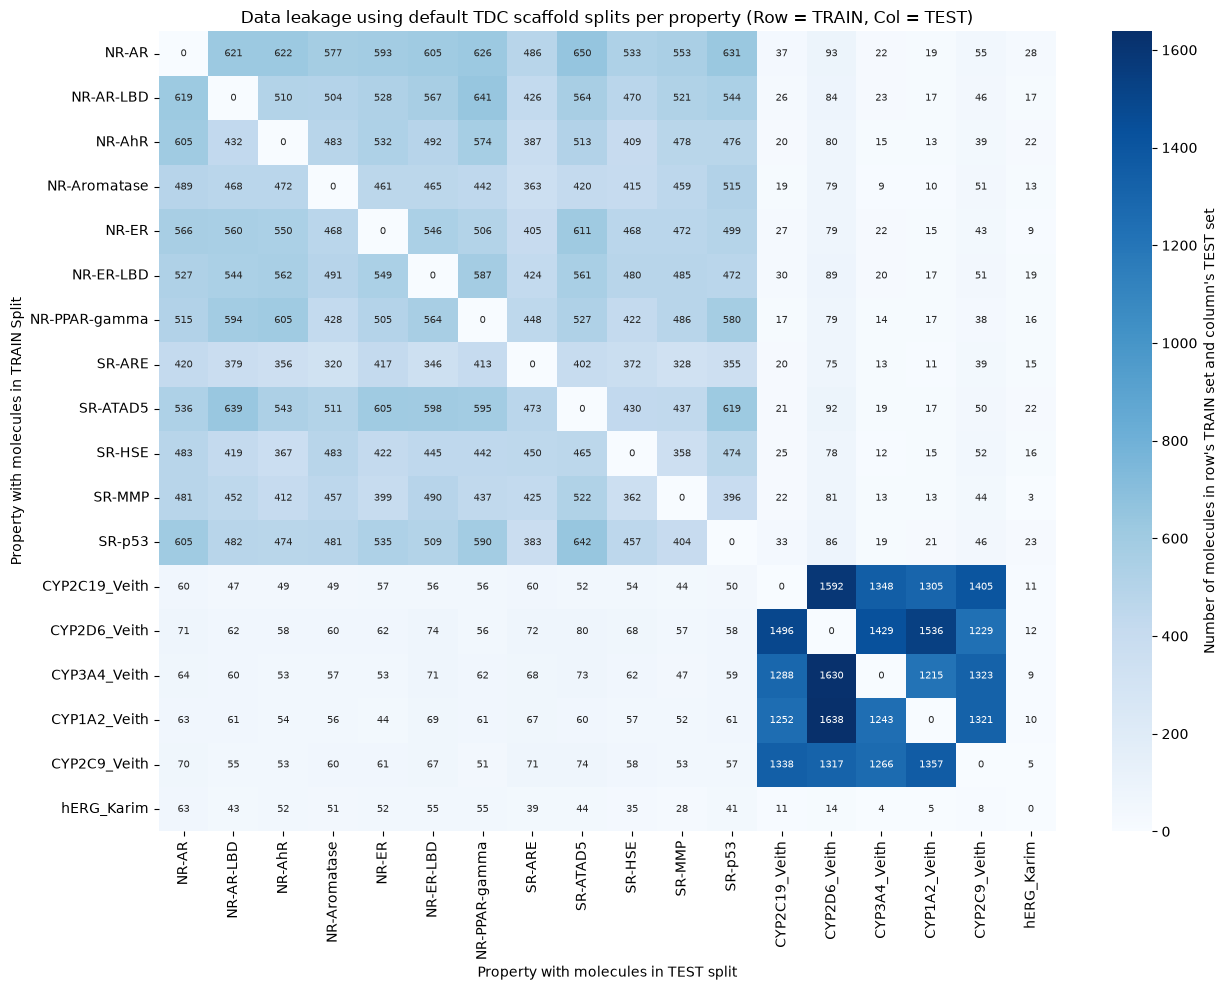

In [21]:
# Call TDC's default per-endpoint scaffold split on each of the 18 loaders
# and map the "Drug" column to canonical SMILES sets for {'train', 'valid', 'test'}
orig_splits = {}

#disable progress bars
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    for task in ALL_TASKS:
        split_dict = tdc_loaders[task].get_split(method="scaffold")
        orig_splits[task] = {
            split_name: set(split_df["Drug"].map(raw_smiles_to_canonical).dropna())
            for split_name, split_df in split_dict.items()
        }

# check which split names ('train', 'valid', 'test') each molecule is assigned to across all properties
mol_assigned_splits = defaultdict(set)
for task, sp_dict in orig_splits.items():
    for split_name, mol_set in sp_dict.items():
        for mol_smi in mol_set:
            mol_assigned_splits[mol_smi].add(split_name)

n_leaked = sum(1 for s_set in mol_assigned_splits.values() if len(s_set) > 1)
n_train_test_leaked = sum(
    1 for s_set in mol_assigned_splits.values() if "train" in s_set and "test" in s_set
)

print(f"Number of molecules assigned to >=2 different splits across tasks: {n_leaked:,} ")
print(f"Number of molecules in TRAIN for one task and TEST for another:    {n_train_test_leaked:,}")

# Build an 18 x 18 matrix where entry (i, j) = number of molecules in property i's TRAIN set and proprty j's TEST set
leak_matrix = np.zeros((len(ALL_TASKS), len(ALL_TASKS)), dtype=int)
for i, task_train in enumerate(ALL_TASKS):
    for j, task_test in enumerate(ALL_TASKS):
        if i != j:
            leak_matrix[i, j] = len(orig_splits[task_train]["train"] & orig_splits[task_test]["test"])

plt.figure(figsize=(13, 10))
sns.heatmap(
    leak_matrix,
    xticklabels=ALL_TASKS, 
    yticklabels=ALL_TASKS,
    annot=True,
    fmt="d",
    cmap="Blues",
    annot_kws={"size": 7.5},
    cbar_kws={"label": "Number of molecules in row's TRAIN set and column's TEST set"},
)
plt.title("Data leakage using default TDC scaffold splits per property (Row = TRAIN, Col = TEST)")
plt.xlabel("Property with molecules in TEST split")
plt.ylabel("Property with molecules in TRAIN Split")
plt.tight_layout()
plt.show()


---
### 5.2 Fixed `70 / 10 / 20` balanced scaffold split (implemented by us in `preprocess.py`)
`preprocess_datasets()` eliminates cross-property leakage by:
1. Grouping all filtered molecules globally by Murcko scaffold.
2. Greedily assigning scaffold groups from largest to smallest to maintain `~70% train / 10% valid / 20% test` and similar positive rates across all 18 properties simultaneously.

In [22]:
canon_smile_to_scaffold = {
    smi: MurckoScaffold.MurckoScaffoldSmiles(mol=Chem.MolFromSmiles(smi), includeChirality=False)
    for smi in multitask_df.index
}

# disable logs from downloading dataset inside preprocess_datasets function
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    train_df, valid_df, test_df, meta = preprocess_datasets(filter_zero_bonds=True)

train_scaffolds = {canon_smile_to_scaffold[s] for s in train_df["smiles"]}
val_scaffolds = {canon_smile_to_scaffold[s] for s in valid_df["smiles"]}
test_scaffolds = {canon_smile_to_scaffold[s] for s in test_df["smiles"]}

print(f"Split sizes: Train: {len(train_df):,} / Validation: {len(valid_df):,} | Test: {len(test_df):,}")
print(f"Scaffolds overlap:")
print(f"Train and Validation: {len(train_scaffolds & val_scaffolds)}")
print(f"Train and Test:       {len(train_scaffolds & test_scaffolds)}") 
print(f"Validation and Test:  {len(val_scaffolds & test_scaffolds)}")  


# Summarize per-property split proportions, positive rates, and training loss weights
split_summary_df = pd.DataFrame([
    {
        "Property": task,
        "Total molecules": info["total_count"],
        "Split % (Train / Validation / Test)": (
            f"{info['train_count'] / info['total_count'] * 100:.1f} / "
            f"{info['valid_count'] / info['total_count'] * 100:.1f} / "
            f"{info['test_count'] / info['total_count'] * 100:.1f}"
        ),
        "Positive label % (Train / Validation / Test)": (
            f"{info['train_pos_rate'] * 100:.2f}% / "
            f"{info['valid_pos_rate'] * 100:.2f}% / "
            f"{info['test_pos_rate'] * 100:.2f}%"
        ),
        "Within-task pos_weight": info["pos_weight"],
        "Across-task task_weight": info["task_weight"],
    }
    for task, info in meta["properties"].items()
])
split_summary_df


Split sizes: Train: 25,660 / Validation: 3,770 | Test: 7,373
Scaffolds overlap:
Train and Validation: 0
Train and Test:       0
Validation and Test:  0


,Property,Total molecules,Split % (Train / Validation / Test),Positive label % (Train / Validation / Test),Within-task pos_weight,Across-task task_weight
0,NR-AR,7239,69.8 / 10.2 / 20.0,4.04% / 5.69% / 4.28%,23.7696,1.0670
1,NR-AR-LBD,6734,69.9 / 10.2 / 20.0,3.34% / 5.12% / 3.27%,28.9745,1.1456
2,NR-AhR,6523,70.0 / 10.0 / 20.0,11.75% / 11.66% / 11.75%,7.5084,1.1800
3,NR-Aromatase,5799,70.0 / 10.0 / 20.0,5.17% / 5.02% / 5.18%,18.3429,1.3273
4,NR-ER,6169,70.1 / 10.0 / 20.0,12.86% / 12.70% / 12.74%,6.7752,1.2471
5,NR-ER-LBD,6930,70.0 / 10.0 / 20.0,5.05% / 4.91% / 4.98%,18.8082,1.1109
6,NR-PPAR-gamma,6426,70.1 / 9.9 / 20.0,2.89% / 2.82% / 2.88%,33.6308,1.1976
7,SR-ARE,5810,70.0 / 10.0 / 20.0,16.17% / 16.21% / 16.11%,5.1839,1.3250
8,SR-ATAD5,7048,70.0 / 10.0 / 20.0,3.75% / 3.68% / 3.69%,25.6649,1.0929
9,SR-HSE,6441,70.0 / 10.0 / 20.0,5.74% / 5.60% / 5.74%,16.4093,1.1957


---
### 5.3 5-Fold Cross-Validation scaffold splits (implemented by us in `preprocess.py`)
`preprocess_cv_datasets(n_folds=5)` isolates the 20% `test_df` as the fixed split and partitions the remaining 80% development set into 5 mutually exclusive, scaffold-disjoint folds.

In [23]:
# disable logs from downloading dataset inside preprocess_datasets function
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    folds, cv_test_df, cv_meta = preprocess_cv_datasets(n_folds=5, filter_zero_bonds=True)

# Verify zero scaffold overlap across all 5 validation folds and the held-out test set
per_fold_scaffold_sets = [{canon_smile_to_scaffold[s] for s in fold["valid_df"]["smiles"]} for fold in folds]
cv_test_scafs = {canon_smile_to_scaffold[s] for s in cv_test_df["smiles"]}

max_pairwise_scaf_overlap = max(
    len(per_fold_scaffold_sets[i] & per_fold_scaffold_sets[j])
    for i in range(5)
    for j in range(i + 1, 5)
)
max_test_scaf_overlap = max(len(per_fold_scaffold_sets[i] & cv_test_scafs) for i in range(5))

print(f"5-Fold Cross-Validation validation fold sizes: {cv_meta['split_counts']['fold_valid']}")
print(f"Test size: {len(cv_test_df):,}")
print(f"Max scaffold overlap between any two Cross-Validation folds: {max_pairwise_scaf_overlap}")
print(f"Max scaffold overlap between any of the folds and test set: {max_test_scaf_overlap}")

# Summarize per-endpoint sample sizes and positive class rates across all 5 validation folds
cv_summary_rows = []
for task, info in cv_meta["properties"].items():
    total_count = info["total_count"]
    counts = info["fold_valid_counts"]
    pos_pcts = [rate * 100 for rate in info["fold_valid_pos_rates"]]
    cv_summary_rows.append({
        "Endpoint": task,
        "Train + validation molecules count (80%)": info["dev_count"],
        "Test molecules count (20%)": info["test_count"],
        "Validation % per fold (F0 / F1 / F2 / F3 / F4)": " / ".join(f"{c / total_count * 100:.1f}" for c in counts),
        "Positive label in validation % per fold (F0 / F1 / F2 / F3 / F4)": " / ".join(f"{p:.1f}%" for p in pos_pcts),
    })

display(pd.DataFrame(cv_summary_rows))


5-Fold Cross-Validation validation fold sizes: {0: 6184, 1: 6465, 2: 5590, 3: 5615, 4: 5576}
Test size: 7,373
Max scaffold overlap between any two Cross-Validation folds: 0
Max scaffold overlap between any of the folds and test set: 0


,Endpoint,Train + validation molecules count (80%),Test molecules count (20%),Validation % per fold (F0 / F1 / F2 / F3 / F4),Positive label in validation % per fold (F0 / F1 / F2 / F3 / F4)
0,NR-AR,5791,1448,19.1 / 23.3 / 12.5 / 12.6 / 12.5,1.7% / 1.1% / 7.5% / 7.5% / 7.5%
1,NR-AR-LBD,5390,1344,19.5 / 24.3 / 12.1 / 12.1 / 12.1,1.6% / 1.7% / 5.9% / 5.9% / 5.8%
2,NR-AhR,5221,1302,19.1 / 24.6 / 12.1 / 12.1 / 12.1,12.6% / 1.7% / 18.1% / 18.1% / 18.1%
3,NR-Aromatase,4640,1159,19.8 / 26.0 / 11.4 / 11.4 / 11.4,2.9% / 1.2% / 9.4% / 9.5% / 9.5%
4,NR-ER,4937,1232,19.7 / 25.0 / 11.8 / 11.8 / 11.8,11.4% / 6.4% / 18.3% / 18.1% / 18.2%
5,NR-ER-LBD,5545,1385,19.5 / 23.9 / 12.2 / 12.2 / 12.2,3.9% / 2.4% / 7.3% / 7.5% / 7.3%
6,NR-PPAR-gamma,5141,1285,20.0 / 25.3 / 11.6 / 11.5 / 11.6,1.9% / 2.5% / 3.8% / 3.8% / 3.8%
7,SR-ARE,4649,1161,21.1 / 25.8 / 11.0 / 11.1 / 11.0,11.6% / 9.5% / 24.3% / 24.4% / 24.3%
8,SR-ATAD5,5639,1409,19.3 / 23.9 / 12.3 / 12.3 / 12.3,2.6% / 2.4% / 5.2% / 5.2% / 5.2%
9,SR-HSE,5152,1289,20.6 / 24.7 / 11.6 / 11.6 / 11.5,4.4% / 4.8% / 7.1% / 7.3% / 7.1%
